In [65]:
import numpy as np
import pandas as pd
import kagglehub
path = kagglehub.dataset_download("fatemehmehrparvar/obesity-levels")
import os
csv_path = os.path.join(path, "ObesityDataSet_raw_and_data_sinthetic.csv")
data = pd.read_csv(csv_path)

In [66]:
data.head()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [67]:
data.isna().sum()

Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [68]:
data.duplicated().sum()

np.int64(24)

In [69]:
data.drop_duplicates(inplace=True)

C:\Users\khale\AppData\Local\Temp\ipykernel_22728\2282015914.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop_duplicates(inplace=True)


In [70]:
data.info()

<class 'pandas.DataFrame'>
Index: 2087 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2087 non-null   float64
 1   Gender                          2087 non-null   str    
 2   Height                          2087 non-null   float64
 3   Weight                          2087 non-null   float64
 4   CALC                            2087 non-null   str    
 5   FAVC                            2087 non-null   str    
 6   FCVC                            2087 non-null   float64
 7   NCP                             2087 non-null   float64
 8   SCC                             2087 non-null   str    
 9   SMOKE                           2087 non-null   str    
 10  CH2O                            2087 non-null   float64
 11  family_history_with_overweight  2087 non-null   str    
 12  FAF                             2087 non-null   fl

In [71]:
data.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [72]:
data.describe(include='object')

C:\Users\khale\AppData\Local\Temp\ipykernel_22728\3382516499.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include='object')


,Gender,CALC,FAVC,SCC,SMOKE,family_history_with_overweight,CAEC,MTRANS,NObeyesdad
count,2087,2087,2087,2087,2087,2087,2087,2087,2087
unique,2,4,2,2,2,2,4,5,7
top,Male,Sometimes,yes,no,no,yes,Sometimes,Public_Transportation,Obesity_Type_I
freq,1052,1380,1844,1991,2043,1722,1761,1558,351


In [73]:
continuous_features = ['Age', 'Height', 'Weight']

ordinal_features = ['FCVC', 'CH2O', 'FAF', 'TUE']

discrete_features = ['NCP']

numerical_features = (
    continuous_features +
    ordinal_features +
    discrete_features
)

In [74]:
from sklearn.model_selection import train_test_split
X=data.drop('NObeyesdad',axis=1)
y=data['NObeyesdad']
X_train, X_test, y_train, y_test = train_test_split(data.drop('NObeyesdad', axis=1), data['NObeyesdad'], test_size=0.2, random_state=42)

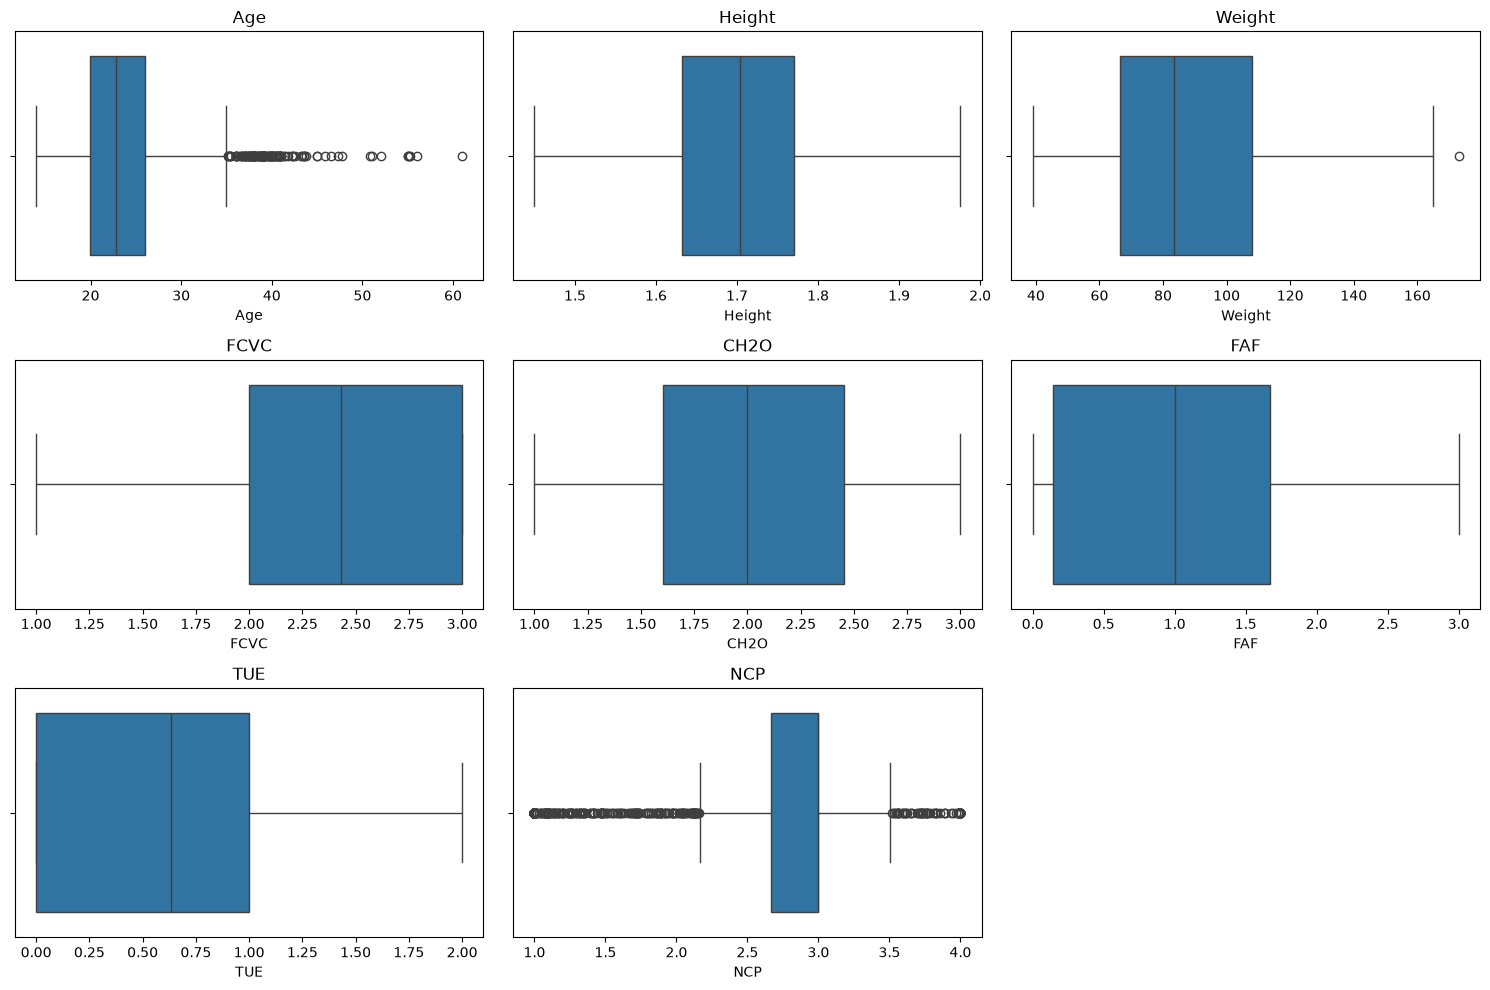

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=X_train[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [76]:
X_train['NCP'].value_counts().sort_index()

NCP
1.000000    147
1.000283      1
1.000610      1
1.001383      1
1.001542      1
           ... 
3.994588      1
3.995147      1
3.998618      1
3.998766      1
4.000000     52
Name: count, Length: 510, dtype: int64

In [77]:
X_train['NCP'] = X_train['NCP'].round().astype(int)
X_test['NCP'] = X_test['NCP'].round().astype(int)

In [78]:
X_train['NCP'].value_counts().sort_index()

NCP
1     243
2     144
3    1171
4     111
Name: count, dtype: int64

In [79]:
Q1 = X_train['NCP'].quantile(0.25)
Q3 = X_train['NCP'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = X_train[
    (X_train['NCP'] < lower) |
    (X_train['NCP'] > upper)
]

print("Outliers:", len(outliers))

Outliers: 498


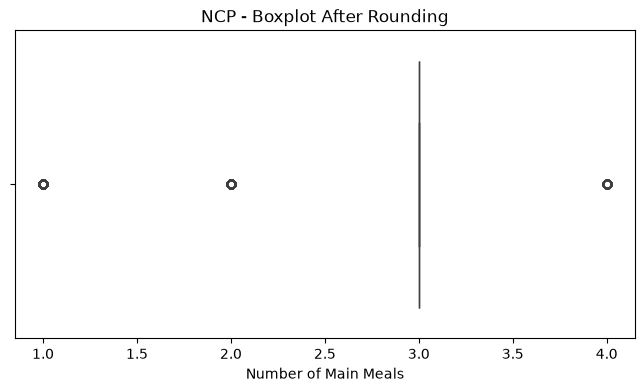

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.boxplot(x=X_train['NCP'])

plt.title('NCP - Boxplot After Rounding')
plt.xlabel('Number of Main Meals')

plt.show()

In [81]:
for col in X_train.columns:
    print(f"\n{'='*40}")
    print(f"Value Counts for {col}")
    print('='*40)
    print(X_train[col].value_counts(dropna=False))


Value Counts for Age
Age
18.000000    102
23.000000     73
26.000000     70
21.000000     61
19.000000     45
            ... 
23.083621      1
35.456326      1
22.882558      1
23.237302      1
17.781183      1
Name: count, Length: 1139, dtype: int64

Value Counts for Gender
Gender
Male      850
Female    819
Name: count, dtype: int64

Value Counts for Height
Height
1.700000    45
1.650000    42
1.600000    33
1.750000    32
1.800000    21
            ..
1.947406     1
1.848553     1
1.651812     1
1.793451     1
1.761008     1
Name: count, Length: 1272, dtype: int64

Value Counts for Weight
Weight
80.000000     46
75.000000     31
60.000000     28
50.000000     25
70.000000     22
              ..
116.893105     1
121.421121     1
79.437921      1
89.909259      1
97.829344      1
Name: count, Length: 1242, dtype: int64

Value Counts for CALC
CALC
Sometimes     1113
no             498
Frequently      57
Always           1
Name: count, dtype: int64

Value Counts for FAVC
FAVC
yes    

In [82]:
from sklearn.model_selection import train_test_split
X=data.drop('NObeyesdad',axis=1)
y=data['NObeyesdad']
X_train, X_test, y_train, y_test = train_test_split(data.drop('NObeyesdad', axis=1), data['NObeyesdad'], test_size=0.2, random_state=42)

In [83]:
categorical_features = [
    'Gender',
    'family_history_with_overweight',
    'FAVC',
    'CAEC',
    'SMOKE',
    'SCC',
    'CALC',
    'MTRANS'
]

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

In [85]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [86]:
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['Insufficient_Weight','Normal_Weight','Obesity_Type_I',..., 'Obesity_Type_III','Overweight_Level_I','Overweight_Level_II']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Gender','Height',...,'TUE','CAEC','MTRANS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the n

In [91]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model_pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9473684210526315
                     precision    recall  f1-score   support

Insufficient_Weight       0.96      0.90      0.93        59
      Normal_Weight       0.80      0.93      0.86        61
     Obesity_Type_I       1.00      0.96      0.98        70
    Obesity_Type_II       1.00      1.00      1.00        64
   Obesity_Type_III       1.00      1.00      1.00        60
 Overweight_Level_I       0.94      0.87      0.91        55
Overweight_Level_II       0.94      0.96      0.95        49

           accuracy                           0.95       418
          macro avg       0.95      0.95      0.95       418
       weighted avg       0.95      0.95      0.95       418



In [93]:
user = X_test.iloc[[0]]
user_transformed = preprocessor.transform(user)

prediction = model_pipeline.predict(user)[0]

print("Predicted class:", prediction)

Predicted class: Obesity_Type_I


In [95]:
import joblib

joblib.dump(model_pipeline, 'obesity_model_pipeline.pkl')

['obesity_model_pipeline.pkl']

In [96]:
import shap

preprocessor = model_pipeline.named_steps['preprocessor']
classifier = model_pipeline.named_steps['classifier']

X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_test_transformed)